In [15]:
# Climate Data we choose ERA5 land 2m air temperature
import numpy as np
import xarray as xr
import rioxarray as rxr
import matplotlib.pyplot as plt

ds = xr.open_dataset('data_raw/era5_land_2m_temp.nc')
ds

<xarray.Dataset> Size: 1MB
Dimensions:     (valid_time: 104, latitude: 31, longitude: 81)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 832B 2000-05-01 ... 2025-08-01
  * latitude    (latitude) float64 248B 48.0 47.9 47.8 47.7 ... 45.2 45.1 45.0
  * longitude   (longitude) float64 648B 5.0 5.1 5.2 5.3 ... 12.7 12.8 12.9 13.0
    expver      (valid_time) <U4 2kB ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 1MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-03-15T06:29 GRIB to CDM+CF via cfgrib-0.9.1...

In [3]:
# Extracting temperature in Kelvins default in ERA5
temp_K = ds['t2m']

#convert to deg celsius
temp_C = temp_K - 273.15

print(float(temp_C.min()), float(temp_C.max()))

-4.585296630859375 29.017730712890625


In [4]:
# Computing Breeding Season
breeding_temp = temp_C.mean(dim='valid_time')
breeding_temp

<xarray.DataArray 't2m' (latitude: 31, longitude: 81)> Size: 10kB
array([[17.639957, 17.463295, 17.263344, ..., 16.887442, 16.889996,
        16.686983],
       [17.40288 , 17.257032, 17.102041, ..., 16.791176, 16.884005,
        16.761295],
       [17.26603 , 17.175472, 17.147621, ..., 15.509344, 16.389225,
        16.623789],
       ...,
       [19.066414, 18.703829, 18.941038, ...,       nan,       nan,
              nan],
       [19.786894, 19.671583, 19.517004, ...,       nan,       nan,
              nan],
       [19.687151, 18.953884, 18.151056, ...,       nan,       nan,
              nan]], dtype=float32)
Coordinates:
    number     int64 8B ...
  * latitude   (latitude) float64 248B 48.0 47.9 47.8 47.7 ... 45.2 45.1 45.0
  * longitude  (longitude) float64 648B 5.0 5.1 5.2 5.3 ... 12.7 12.8 12.9 13.0

In [6]:
breeding_temp = breeding_temp.rio.write_crs("EPSG:4326")
breeding_temp

<xarray.DataArray 't2m' (latitude: 31, longitude: 81)> Size: 10kB
array([[17.639957, 17.463295, 17.263344, ..., 16.887442, 16.889996,
        16.686983],
       [17.40288 , 17.257032, 17.102041, ..., 16.791176, 16.884005,
        16.761295],
       [17.26603 , 17.175472, 17.147621, ..., 15.509344, 16.389225,
        16.623789],
       ...,
       [19.066414, 18.703829, 18.941038, ...,       nan,       nan,
              nan],
       [19.786894, 19.671583, 19.517004, ...,       nan,       nan,
              nan],
       [19.687151, 18.953884, 18.151056, ...,       nan,       nan,
              nan]], dtype=float32)
Coordinates:
    number       int64 8B ...
  * latitude     (latitude) float64 248B 48.0 47.9 47.8 47.7 ... 45.2 45.1 45.0
  * longitude    (longitude) float64 648B 5.0 5.1 5.2 5.3 ... 12.8 12.9 13.0
    spatial_ref  int32 4B 0

In [11]:
dem_1kmres = rxr.open_rasterio("data_processed/dem_1km_res.tif").squeeze()
dem_1kmres

<xarray.DataArray (y: 301, x: 801)> Size: 482kB
[241101 values with dtype=int16]
Coordinates:
    band         int32 4B 1
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
    spatial_ref  int32 4B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     -32768
    scale_factor:   1.0
    add_offset:     0.0

In [19]:
climate_1kmres = breeding_temp.rio.reproject_match(dem_1kmres)

#save file
climate_1kmres.rio.to_raster("data_processed/breeding_temp_1km.tif")

climate_1kmres


C:\Users\91702\anaconda3\lib\site-packages\rioxarray\raster_writer.py:130: UserWarning: The nodata value (3.402823466e+38) has been automatically changed to (3.4028234663852886e+38) to match the dtype of the data.
  warnings.warn(


<xarray.DataArray 't2m' (y: 301, x: 801)> Size: 964kB
array([[17.639957, 17.639957, 17.639957, ..., 16.686983, 16.686983,
        16.686983],
       [17.639957, 17.639957, 17.639957, ..., 16.686983, 16.686983,
        16.686983],
       [17.639957, 17.639957, 17.639957, ..., 16.686983, 16.686983,
        16.686983],
       ...,
       [19.687151, 19.687151, 19.687151, ...,       nan,       nan,
              nan],
       [19.687151, 19.687151, 19.687151, ...,       nan,       nan,
              nan],
       [19.687151, 19.687151, 19.687151, ...,       nan,       nan,
              nan]], dtype=float32)
Coordinates:
    number       int64 8B 0
    spatial_ref  int32 4B 0
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
Attributes:
    _FillValue:  3.402823466e+38

In [22]:
print(climate_1kmres.shape)
print(dem_1kmres.shape)
print(breeding_temp.shape)

(301, 801)
(301, 801)
(31, 81)


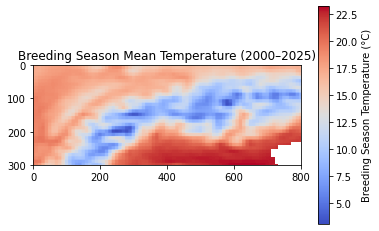

In [21]:
# EDA of climate map
plt.imshow(climate_1kmres, cmap="coolwarm")
plt.colorbar(label="Breeding Season Temperature (°C)")
plt.title("Breeding Season Mean Temperature (2000–2025)")
plt.show()